In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.preprocessing import  OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector

In [3]:
housing = pd.read_csv("Housing.csv")
X = housing.drop('price', axis=1)
y = housing['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=25)

In [52]:
---------------------

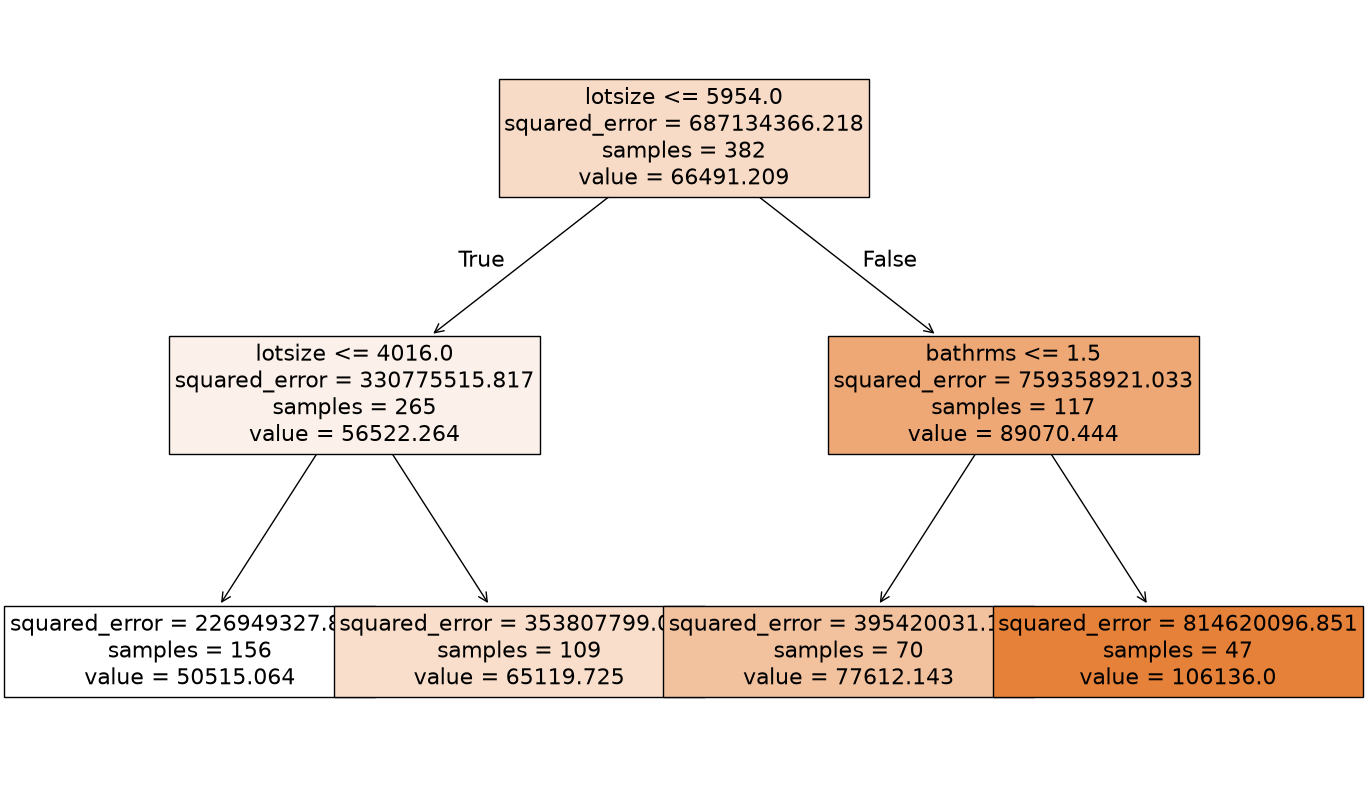

In [53]:
------------------------
dtr.fit(X_train_trns, y_train)
plt.figure(figsize=(17,10))
plot_tree(dtr, feature_names=list(X_train_trns.columns),filled=True,fontsize=16)
plt.show() 

In [54]:
y_train.mean()

np.float64(66491.20942408378)

In [55]:
np.mean((y_train - y_train.mean())**2)

np.float64(687134366.2179216)

In [56]:
y_left = y_train[X_train['lotsize']<=5954]
y_left.mean()

np.float64(56522.264150943396)

In [57]:
y_right = y_train[X_train['lotsize']>5954]
y_right.mean()

np.float64(89070.44444444444)

In [58]:
-------
---------------
--------------------
----------------
for d in depths:
    for l in leaves:
        for s in splits:
            dtc = DecisionTreeRegressor(random_state=25, max_depth=d,
                                         min_samples_leaf=l, min_samples_split=s)
            dtc.fit(X_train_trns, y_train)
            y_pred = dtc.predict(X_test_trns)
            scores.append([d,l,s, r2_score(y_test, y_pred )] )
df_scores = pd.DataFrame( scores, columns=['depth','leaf','split','score'] )
df_scores.sort_values( 'score', ascending=False )

,depth,leaf,split,score
103,8.0,1,20,0.520188
108,8.0,5,20,0.517948
128,NaN,1,20,0.516177
78,5.0,1,20,0.514985
133,NaN,5,20,0.513971
...,...,...,...,...
127,NaN,1,10,0.344446
101,8.0,1,5,0.339508
126,NaN,1,5,0.286563
100,8.0,1,2,0.282023


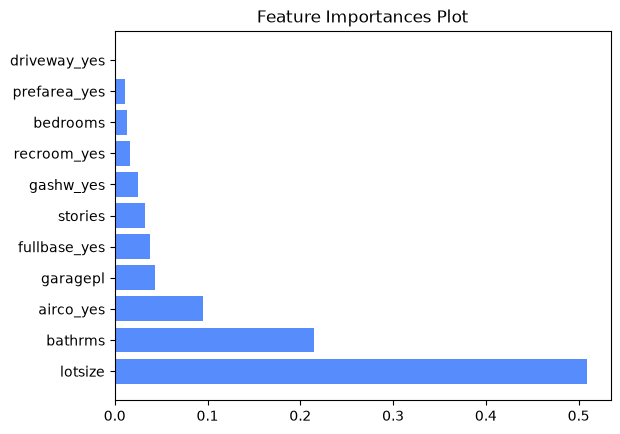

In [59]:
best_tree = DecisionTreeRegressor(random_state=25, max_depth=8,
                                  min_samples_leaf=1, min_samples_split=20)
X_trns = trns.fit_transform(X)
best_tree.fit(X_trns, y)
df_imp = pd.DataFrame({'feature':list(X_trns.columns),'imp': best_tree.feature_importances_})
df_imp = df_imp.sort_values('imp', ascending=False)
plt.barh(df_imp['feature'], df_imp['imp'])
plt.title("Feature Importances Plot")
plt.show()

In [60]:
housing.groupby('bathrms')['price'].mean()

bathrms
1     60153.233831
2     88702.947368
3    104030.000000
4    175000.000000
Name: price, dtype: float64